# 第六部分：SQL Skills Assistant — 按需加载数据库技能的渐进式披露
### *让 Agent 像 DBA 一样按需翻看不同业务线的数据字典，并自动生成可视化图表*

大型企业通常有多个业务数据源（销售、库存、财务等），如果将所有 Schema 一次性注入 System Prompt，Token 很快就会被耗尽。

**本 Notebook 实践：**
1. 为 `sales_analytics` 和 `inventory_management` 两个业务域创建 `SKILL.md`（包含表结构 + 业务逻辑 + 示例 SQL）
2. Agent 启动时**只加载技能名和描述**（目录），收到具体问题后**按需调用 `read_skill` 加载完整 Schema**
3. 使用 `execute_sql` 工具连接 SQLite 数据库，执行生成的 SQL 查询
4. 使用 `generate_chart` 工具将查询结果自动可视化为图表

**核心概念：** Progressive Disclosure — 和 Notebook 5 相同，但这次应用于数据库查询 + 可视化场景。

In [1]:
import os
import sqlite3
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
from langchain_core.tools import tool
from langgraph.checkpoint.memory import MemorySaver
from deepagents import create_deep_agent
from deepagents.backends.filesystem import FilesystemBackend
from deepagents.middleware.skills import SKILLS_SYSTEM_PROMPT

load_dotenv(override=True)

root_dir = Path.cwd()
DB_PATH = root_dir / "enterprise_data" / "commerce.db"

print("=== DeepAgent Skills Middleware 自动注入的提示词 ===\n")
print(SKILLS_SYSTEM_PROMPT)
print("=" * 60)

=== DeepAgent Skills Middleware 自动注入的提示词 ===

## Skills System

You have access to a skills library that provides specialized capabilities and domain knowledge.

{skills_locations}{skills_load_warnings}

Sources labeled "Deepagents" are specific to this agent tool; sources labeled "Agents" are shared across all agent tools on this machine.

**Available Skills:**

{skills_list}

**How to Use Skills (Progressive Disclosure):**

Skills follow a **progressive disclosure** pattern - you see their name and description above, but only read full instructions when needed:

1. **Recognize when a skill applies**: Check if the user's task matches a skill's description
2. **Read the skill's full instructions**: Use `read_file` on the path shown in the skill list above.
    Pass `limit=1000` since the default of 100 lines is too small for most skill files.
3. **Follow the skill's instructions**: SKILL.md contains step-by-step workflows, best practices, and examples
4. **Access supporting files**: Sk

### 技能系统（Skills System）说明

上面这段提示词是 `deepagents` 中间件**自动注入**到 Agent 的 System Prompt 中的。它告诉 Agent：

1. **你有技能库可用** — 每个技能是一份专门的领域知识手册（SKILL.md）
2. **但只看目录，不读全文** — Agent 初始化时只加载技能的 `name` 和 `description`（轻量目录）
3. **按需阅读** — 只有当 Agent 判断某个技能适用于当前任务时，才通过 `read_file` 工具读取完整的 SKILL.md

**核心原则：渐进式披露（Progressive Disclosure）**

```
用户提问 → Agent 看技能目录 → 匹配到相关技能 → read_file 加载全文 → 按规则执行
                 (轻量)                     (按需)              (精准)
```

**优势：**
- 🎯 **Token 效率**：初始请求非常短，不浪费 Token
- 🚫 **零干扰**：不相关的技能规则不会被加载，避免幻觉
- 🔄 **动态更新**：修改 SKILL.md 后，Agent 下次 `read_file` 立即获得新知识

在本 Notebook 中，`sales_analytics` 和 `inventory_management` 两个技能就是按照这个模式工作的。

## 1. 创建工具：SQL 执行 + 图表生成

Agent 通过 `execute_sql` 来查询数据库，通过 `generate_chart` 将查询结果可视化为图表。

`generate_chart` 会自动：
1. 执行 SQL 获取数据
2. 识别标签列（第一列）和数值列（第二列及以后）
3. 根据数据特点选择合适的图表类型（柱状图/饼图/折线图/横向柱状图）
4. 将图表保存到 `enterprise_data/` 目录并返回路径

In [2]:
@tool
def execute_sql(sql: str) -> str:
    """Execute a SQL query on the commerce database and return results.
    
    The database contains tables: customers, orders, order_items,
    products, warehouses, inventory, stock_movements.
    
    Args:
        sql: The SQL query to execute
        
    Returns:
        Query results as a formatted string, or an error message
    """
    try:
        conn = sqlite3.connect(str(DB_PATH))
        conn.row_factory = sqlite3.Row
        cursor = conn.execute(sql)
        rows = cursor.fetchall()
        
        if not rows:
            return "Query executed successfully. No rows returned."
        
        # Format as a simple table for text display
        columns = [desc[0] for desc in cursor.description]
        result = " | ".join(columns) + "\n"
        result += "-" * len(result) + "\n"
        for row in rows:
            result += " | ".join(str(v) for v in row) + "\n"
        result += f"\n({len(rows)} rows returned)"
        conn.close()
        return result
    except sqlite3.Error as e:
        return f"SQL Error: {e}"


@tool
def generate_chart(sql: str, chart_type: str = "auto", title: str = "") -> str:
    """Execute a SQL query and generate a chart visualization.
    
    The first column of the query result is used as labels (categories),
    and the second column is used as values.
    
    Args:
        sql: SQL query returning at least 2 columns (label_col, value_col)
        chart_type: "bar", "pie", "line", "horizontal_bar", or "auto" (auto-detect)
        title: Chart title (optional, auto-generated if empty)
        
    Returns:
        Path to the saved chart image, or an error message
    """
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    import numpy as np
    
    # Configure Chinese font support
    plt.rcParams["font.sans-serif"] = ["PingFang SC", "Arial Unicode MS", "DejaVu Sans"]
    plt.rcParams["axes.unicode_minus"] = False
    
    try:
        # Execute the SQL query
        conn = sqlite3.connect(str(DB_PATH))
        cursor = conn.execute(sql)
        rows = cursor.fetchall()
        columns = [desc[0] for desc in cursor.description]
        conn.close()
        
        if not rows or len(columns) < 2:
            return "Error: Query must return at least 2 columns (labels and values)."
        
        # Extract labels (first column) and values (second column)
        labels = [str(row[0]) for row in rows]
        values = [float(row[1]) if row[1] is not None else 0 for row in rows]
        
        # Auto-detect chart type if set to "auto"
        if chart_type == "auto":
            num_categories = len(labels)
            if num_categories <= 6 and all(v >= 0 for v in values):
                chart_type = "pie"  # Few categories, all positive -> pie
            elif num_categories <= 6:
                chart_type = "bar"  # Few categories with mixed signs -> bar
            else:
                chart_type = "horizontal_bar"  # Many categories -> horizontal for readability
        
        # Auto-generate title if empty
        if not title:
            title = f"{columns[0]} vs {columns[1]}"
        
        # Create the chart
        fig, ax = plt.subplots(figsize=(10, 6))
        
        if chart_type == "pie":
            colors = plt.cm.Set3(np.linspace(0, 1, len(labels)))
            wedges, texts, autotexts = ax.pie(
                values, labels=labels, autopct="%1.1f%%", startangle=140,
                colors=colors, wedgeprops={"edgecolor": "white", "linewidth": 1.5},
            )
            centre_circle = plt.Circle((0, 0), 0.70, fc="white")
            ax.add_artist(centre_circle)
            ax.set_title(title, fontsize=14, fontweight="bold", pad=20)
            
        elif chart_type == "bar":
            x = np.arange(len(labels))
            bars = ax.bar(x, values, color=plt.cm.viridis(np.linspace(0.2, 0.9, len(labels))), edgecolor="white")
            ax.set_xticks(x)
            ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=10)
            ax.set_title(title, fontsize=14, fontweight="bold")
            ax.set_ylabel(columns[1])
            # Add value labels on bars
            for bar, v in zip(bars, values):
                ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(values)*0.01,
                        f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
            
        elif chart_type == "horizontal_bar":
            y_pos = np.arange(len(labels))
            bars = ax.barh(y_pos, values, color=plt.cm.viridis(np.linspace(0.2, 0.9, len(labels))), edgecolor="white")
            ax.set_yticks(y_pos)
            ax.set_yticklabels(labels, fontsize=10)
            ax.set_title(title, fontsize=14, fontweight="bold")
            ax.set_xlabel(columns[1])
            # Add value labels
            for bar, v in zip(bars, values):
                ax.text(bar.get_width() + max(values)*0.01, bar.get_y() + bar.get_height()/2,
                        f"{v:,.0f}", ha="left", va="center", fontsize=9)
            ax.invert_yaxis()  # Highest value at top
            
        elif chart_type == "line":
            x = np.arange(len(labels))
            ax.plot(x, values, marker="o", linewidth=2, markersize=6, color="#2E86AB")
            ax.set_xticks(x)
            ax.set_xticklabels(labels, rotation=30, ha="right", fontsize=10)
            ax.set_title(title, fontsize=14, fontweight="bold")
            ax.set_ylabel(columns[1])
            ax.grid(axis="y", alpha=0.3)
            # Add value labels
            for i, v in enumerate(values):
                ax.text(i, v + max(values)*0.02, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
        
        plt.tight_layout()
        
        # Save chart
        chart_dir = root_dir / "enterprise_data"
        chart_dir.mkdir(exist_ok=True)
        safe_name = "".join(c if c.isalnum() or c in " _-" else "_" for c in title)[:40]
        out_path = chart_dir / f"chart_{safe_name}.png"
        plt.savefig(out_path, dpi=150, bbox_inches="tight")
        plt.close(fig)
        
        return f"Chart saved: {out_path}"
        
    except Exception as e:
        return f"Chart Error: {type(e).__name__}: {e}"


print("✅ execute_sql tool created")
print("✅ generate_chart tool created")
print(f"   Database: {DB_PATH}")

✅ execute_sql tool created
✅ generate_chart tool created
   Database: /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/enterprise_data/commerce.db


## 2. 初始化 Agent

使用 `create_deep_agent` 并指定 `skills` 目录。Agent 启动时会自动注入技能目录，但**不会**加载完整的 SKILL.md 内容。

工具列表中包含了 `execute_sql` 和 `generate_chart`，Agent 可以在需要时组合使用它们来完成查询 + 可视化。

In [3]:
model = init_chat_model(
    model="agnes-2.0-flash",
    model_provider="openai",
    base_url=os.getenv("AGNES_BASE_URL"),
    api_key=os.getenv("AGNES_API_KEY"),
    streaming=True,
)

backend = FilesystemBackend(root_dir=str(root_dir))
checkpointer = MemorySaver()

agent = create_deep_agent(
    model=model,
    tools=[execute_sql, generate_chart],
    backend=backend,
    skills=[str(root_dir / "skills")],
    checkpointer=checkpointer,
)

print("✅ Agent created with skills from: skills/")

✅ Agent created with skills from: skills/


/var/folders/gw/b1s29s7934s_dbr99tf9x4fm0000gp/T/ipykernel_77633/4089696593.py:9: LangChainDeprecationWarning: `FilesystemBackend` `virtual_mode` default will change in deepagents==0.6.0; please specify `virtual_mode` explicitly. Note: `virtual_mode` is for virtual path semantics (e.g., `CompositeBackend` routing) and optional path-based guardrails; it does not provide sandboxing or process isolation. Security note: leaving `virtual_mode=False` allows absolute paths and `'..'` to bypass `root_dir`. Consult the API reference for details.
  backend = FilesystemBackend(root_dir=str(root_dir))


## 3. 快速查看技能目录

确认一下 skills 目录下的所有技能清单。

In [4]:
skill_dirs = sorted((root_dir / "skills").iterdir())
for sd in skill_dirs:
    if sd.is_dir():
        print(f"📁 {sd.name}/")
        print(f"   SKILL.md: {sd.name}/SKILL.md")

📁 finance_pro/
   SKILL.md: finance_pro/SKILL.md
📁 inventory_management/
   SKILL.md: inventory_management/SKILL.md
📁 market_wizard/
   SKILL.md: market_wizard/SKILL.md
📁 personal_skills/
   SKILL.md: personal_skills/SKILL.md
📁 sales_analytics/
   SKILL.md: sales_analytics/SKILL.md


## 4. 测试渐进式披露 + 图表生成

我们会依次提出不同的业务查询，并同时要求图表。观察 Agent 如何：
1. 看到技能目录（只有名称和描述）
2. 判断需要哪个技能的详细内容 → 调用 `read_skill`
3. 使用 `execute_sql` 执行查询
4. 使用 `generate_chart` 生成可视化

**注意**：输出中的 `🔧 Tool Call` 显示了 Agent 的内部操作。

In [5]:
from utils import stream_agent

query = "找出消费最高的前5位客户，列出他们的姓名、等级和总消费金额，并生成柱状图"

print("=" * 60)
print(f"  Query: {query}")
print("=" * 60)

await stream_agent(
    agent,
    {"messages": [{"role": "user", "content": query}]},
    config={"configurable": {"thread_id": "sql-sales-1"}, "recursion_limit": 50},
)

Skill 'finance_pro' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/finance_pro/SKILL.md does not follow Agent Skills specification: name must be lowercase alphanumeric with single hyphens only. Consider renaming for spec compliance.
Skill 'inventory_management' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/inventory_management/SKILL.md does not follow Agent Skills specification: name must be lowercase alphanumeric with single hyphens only. Consider renaming for spec compliance.
Skill 'market_wizard' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/market_wizard/SKILL.md does not follow Agent Skills specification: name must be lowercase alphanumeric with single hyphens only. Consider renaming for spec compliance.
Skill 'sales_analytics' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/sales_analytics/SKILL.md does not follow Agent Skill

  Query: 找出消费最高的前5位客户，列出他们的姓名、等级和总消费金额，并生成柱状图
Graph: root
Node: SkillsMiddleware.before_agent
Graph: root
Node: PatchToolCallsMiddleware.before_agent
Graph: root
Node: model


╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│                                                                                                                 │
│ 🔧 Tool Call: execute_sql                                                                                       │
│    Args: {                                                                                                      │
│   "sql": "SELECT c.name, c.level, SUM(o.amount) AS total_spent FROM customers c JOIN orders o ON c.id =         │
│ o.customer_id GROUP BY c.id ORDER BY total_spent DESC LIMIT 5"                                                  │
│ }                                                                                                               │
│    ID: call_da54cace3d0a4d498cd15569                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: TodoListMiddleware.after_model
Graph: root
Node: tools


╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ SQL Error: no such column: c.level                                                                              │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

...

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Chart saved:                                                                                                    │
│ /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/enterprise_data/chart_Top 5         │
│ Customers by Total Spending.png                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: model


╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│ 以下是消费最高的前5位客户：                                                                                     │
│                                                                                                                 │
│ | 排名 | 客户名称 | 等级 | 总消费金额 |                                                                         │
│ |------|----------|------|------------|                                                                         │
│ | 1 | Stark Industries | platinum | $47,141.58 |                                                                │
│ | 2 | Oscorp | silver | $40,202.63 |                                                                            │
│ | 3 | Wayne Enterprises | gold | $28,767.86 |                                                                   │
│ | 4 | Globex Inc | gold | $15,418.63 |                                                                          │
│ | 5 | Acme Corp | platinum | $15,049.87 |                                                                       │
│                                                                                                                 │
│ 柱状图已生成并保存。从图中可以清晰地看到这5位客户的消费金额对比，Stark                                          │
│ Industries以超过4.7万美元的消费额位居榜首，远远领先于其他客户。                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: TodoListMiddleware.after_model


{'messages': [HumanMessage(content='找出消费最高的前5位客户，列出他们的姓名、等级和总消费金额，并生成柱状图', additional_kwargs={}, response_metadata={}, id='b8623242-bf9f-46ac-a76d-9aa8008b1f38'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'finish_reason': 'tool_calls', 'model_name': 'agnes-2.0-flash', 'model_provider': 'openai'}, id='lc_run--019efa64-ce90-7551-9eba-f7a80be09a4b', tool_calls=[{'name': 'execute_sql', 'args': {'sql': 'SELECT c.name, c.level, SUM(o.amount) AS total_spent FROM customers c JOIN orders o ON c.id = o.customer_id GROUP BY c.id ORDER BY total_spent DESC LIMIT 5'}, 'id': 'call_da54cace3d0a4d498cd15569', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 7887, 'output_tokens': 66, 'total_tokens': 7946, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}),
  ToolMessage(content='SQL Error: no such column: c.level', name='execute_sql', id='93909e04-be76-4106-b703-b0938e79b711', tool_call_id='cal

In [6]:
from utils import stream_agent

query = "检查哪些产品需要补货（库存低于再订购点），列出产品名称、当前库存量和建议补货数量，并用横向柱状图展示"

print("=" * 60)
print(f"  Query: {query}")
print("=" * 60)

await stream_agent(
    agent,
    {"messages": [{"role": "user", "content": query}]},
    config={"configurable": {"thread_id": "sql-inventory-1"}, "recursion_limit": 50},
)

Skill 'finance_pro' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/finance_pro/SKILL.md does not follow Agent Skills specification: name must be lowercase alphanumeric with single hyphens only. Consider renaming for spec compliance.
Skill 'inventory_management' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/inventory_management/SKILL.md does not follow Agent Skills specification: name must be lowercase alphanumeric with single hyphens only. Consider renaming for spec compliance.
Skill 'market_wizard' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/market_wizard/SKILL.md does not follow Agent Skills specification: name must be lowercase alphanumeric with single hyphens only. Consider renaming for spec compliance.
Skill 'sales_analytics' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/sales_analytics/SKILL.md does not follow Agent Skill

  Query: 检查哪些产品需要补货（库存低于再订购点），列出产品名称、当前库存量和建议补货数量，并用横向柱状图展示
Graph: root
Node: SkillsMiddleware.before_agent
Graph: root
Node: PatchToolCallsMiddleware.before_agent
Graph: root
Node: model


╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│                                                                                                                 │
│ 🔧 Tool Call: execute_sql                                                                                       │
│    Args: {                                                                                                      │
│   "sql": "SELECT p.product_name, i.quantity_in_stock, p.reorder_point, (p.reorder_point * 1.5 -                 │
│ i.quantity_in_stock) AS suggested_reorder_qty\nFROM products p\nJOIN inventory i ON p.product_id =              │
│ i.product_id\nWHERE i.quantity_in_stock < p.reorder_point\nORDER BY i.quantity_in_stock ASC"                    │
│ }                                                                                                               │
│    ID: call_5b0ef63cb4274136a28af1ac                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: TodoListMiddleware.after_model
Graph: root
Node: tools


╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ SQL Error: no such column: i.quantity_in_stock                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

...

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Chart saved:                                                                                                    │
│ /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/enterprise_data/chart_建议补货数量_ │
│ 横向柱状图_.png                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: model


╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│ 以下是需要补货的产品列表：                                                                                      │
│                                                                                                                 │
│ | 产品名称 | 当前总库存 | 再订购点 | 建议补货数量 |                                                             │
│ |----------|-----------|---------|-------------|                                                                │
│ | Legacy Widget | 0 | 50 | 100 |                                                                                │
│ | Component A | 130 | 500 | 870 |                                                                               │
│                                                                                                                 │
│ **分析说明：**                                                                                                  │
│ - **Legacy Widget**：当前库存为 0，远低于再订购点 50，建议补货 100 件。                                         │
│ - **Component A**：当前库存 130，低于再订购点 500，建议补货 870 件以补充到再订购点的两倍水平。                  │
│                                                                                                                 │
│ ![建议补货数量](chart_建议补货数量_横向柱状图_.png)                                                             │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: TodoListMiddleware.after_model


{'messages': [HumanMessage(content='检查哪些产品需要补货（库存低于再订购点），列出产品名称、当前库存量和建议补货数量，并用横向柱状图展示', additional_kwargs={}, response_metadata={}, id='c850de1a-02c9-41d7-8e15-3d1066640341'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'finish_reason': 'tool_calls', 'model_name': 'agnes-2.0-flash', 'model_provider': 'openai'}, id='lc_run--019efa66-f7cf-7832-90e8-20e5e8d2d296', tool_calls=[{'name': 'execute_sql', 'args': {'sql': 'SELECT p.product_name, i.quantity_in_stock, p.reorder_point, (p.reorder_point * 1.5 - i.quantity_in_stock) AS suggested_reorder_qty\nFROM products p\nJOIN inventory i ON p.product_id = i.product_id\nWHERE i.quantity_in_stock < p.reorder_point\nORDER BY i.quantity_in_stock ASC'}, 'id': 'call_5b0ef63cb4274136a28af1ac', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 7898, 'output_tokens': 96, 'total_tokens': 7987, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}),
  Too

In [7]:
from utils import stream_agent

query = "按产品类别统计总销售额，显示每个类别的名称和总金额，用饼图展示占比"

print("=" * 60)
print(f"  Query: {query}")
print("=" * 60)

await stream_agent(
    agent,
    {"messages": [{"role": "user", "content": query}]},
    config={"configurable": {"thread_id": "sql-category-1"}, "recursion_limit": 50},
)

Skill 'finance_pro' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/finance_pro/SKILL.md does not follow Agent Skills specification: name must be lowercase alphanumeric with single hyphens only. Consider renaming for spec compliance.
Skill 'inventory_management' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/inventory_management/SKILL.md does not follow Agent Skills specification: name must be lowercase alphanumeric with single hyphens only. Consider renaming for spec compliance.
Skill 'market_wizard' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/market_wizard/SKILL.md does not follow Agent Skills specification: name must be lowercase alphanumeric with single hyphens only. Consider renaming for spec compliance.
Skill 'sales_analytics' in /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/skills/sales_analytics/SKILL.md does not follow Agent Skill

  Query: 按产品类别统计总销售额，显示每个类别的名称和总金额，用饼图展示占比
Graph: root
Node: SkillsMiddleware.before_agent
Graph: root
Node: PatchToolCallsMiddleware.before_agent
Graph: root
Node: model


╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│                                                                                                                 │
│                                                                                                                 │
│ 🔧 Tool Call: execute_sql                                                                                       │
│    Args: {                                                                                                      │
│   "sql": "SELECT \n    p.category AS category_name,\n    SUM(oi.quantity * oi.unit_price) AS total_sales\nFROM  │
│ order_items oi\nJOIN products p ON oi.product_id = p.id\nGROUP BY p.category\nORDER BY total_sales DESC"        │
│ }                                                                                                               │
│    ID: call_abe6789c5c584760ac83b156                                                                            │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: TodoListMiddleware.after_model
Graph: root
Node: tools


╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ SQL Error: no such column: p.id                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

...

╭──────────────────────────────────────────────── 🔧 Tool Output ─────────────────────────────────────────────────╮
│ Chart saved:                                                                                                    │
│ /Users/weiping/dev/Learn/langchain-ai/langconfig/backend/notebooks/module-5/enterprise_data/chart_按产品类别统  │
│ 计销售占比.png                                                                                                  │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: model


╭───────────────────────────────────────────────────── 📝 AI ─────────────────────────────────────────────────────╮
│ 以下是按产品类别统计的总销售额：                                                                                │
│                                                                                                                 │
│ | 产品类别 | 总销售额 |                                                                                         │
│ |---------|---------|                                                                                           │
│ | Widgets | ¥87,372.96 |                                                                                        │
│ | Components | ¥76,730.65 |                                                                                     │
│ | Gadgets | ¥62,619.00 |                                                                                        │
│                                                                                                                 │
│ **销售占比分析：**                                                                                              │
│ - **Widgets** 以 87,372.96 元位居第一，占总销售额约 **35.6%**                                                   │
│ - **Components** 以 76,730.65 元位居第二，占约 **31.3%**                                                        │
│ - **Gadgets** 以 62,619.00 元位居第三，占约 **25.5%**                                                           │
│                                                                                                                 │
│ 饼图已生成并保存至 `chart_按产品类别统计销售占比.png`。                                                         │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Graph: root
Node: TodoListMiddleware.after_model


{'messages': [HumanMessage(content='按产品类别统计总销售额，显示每个类别的名称和总金额，用饼图展示占比', additional_kwargs={}, response_metadata={}, id='4a0ac337-5444-4b60-9aef-3f143da91e82'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'finish_reason': 'tool_calls', 'model_name': 'agnes-2.0-flash', 'model_provider': 'openai'}, id='lc_run--019efa69-01eb-7820-8f50-9426c894ea9c', tool_calls=[{'name': 'execute_sql', 'args': {'sql': 'SELECT \n    p.category AS category_name,\n    SUM(oi.quantity * oi.unit_price) AS total_sales\nFROM order_items oi\nJOIN products p ON oi.product_id = p.id\nGROUP BY p.category\nORDER BY total_sales DESC'}, 'id': 'call_abe6789c5c584760ac83b156', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 7885, 'output_tokens': 76, 'total_tokens': 7954, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}}),
  ToolMessage(content='SQL Error: no such column: p.id', name='execute_sql', id='d0ae266f-6031

## 5. 查看生成的图表

所有图表已保存到 `enterprise_data/` 目录。以下是运行过程中生成的图表文件：

Found 3 chart(s):

📊 chart_Top 5 Customers by Total Spending.png


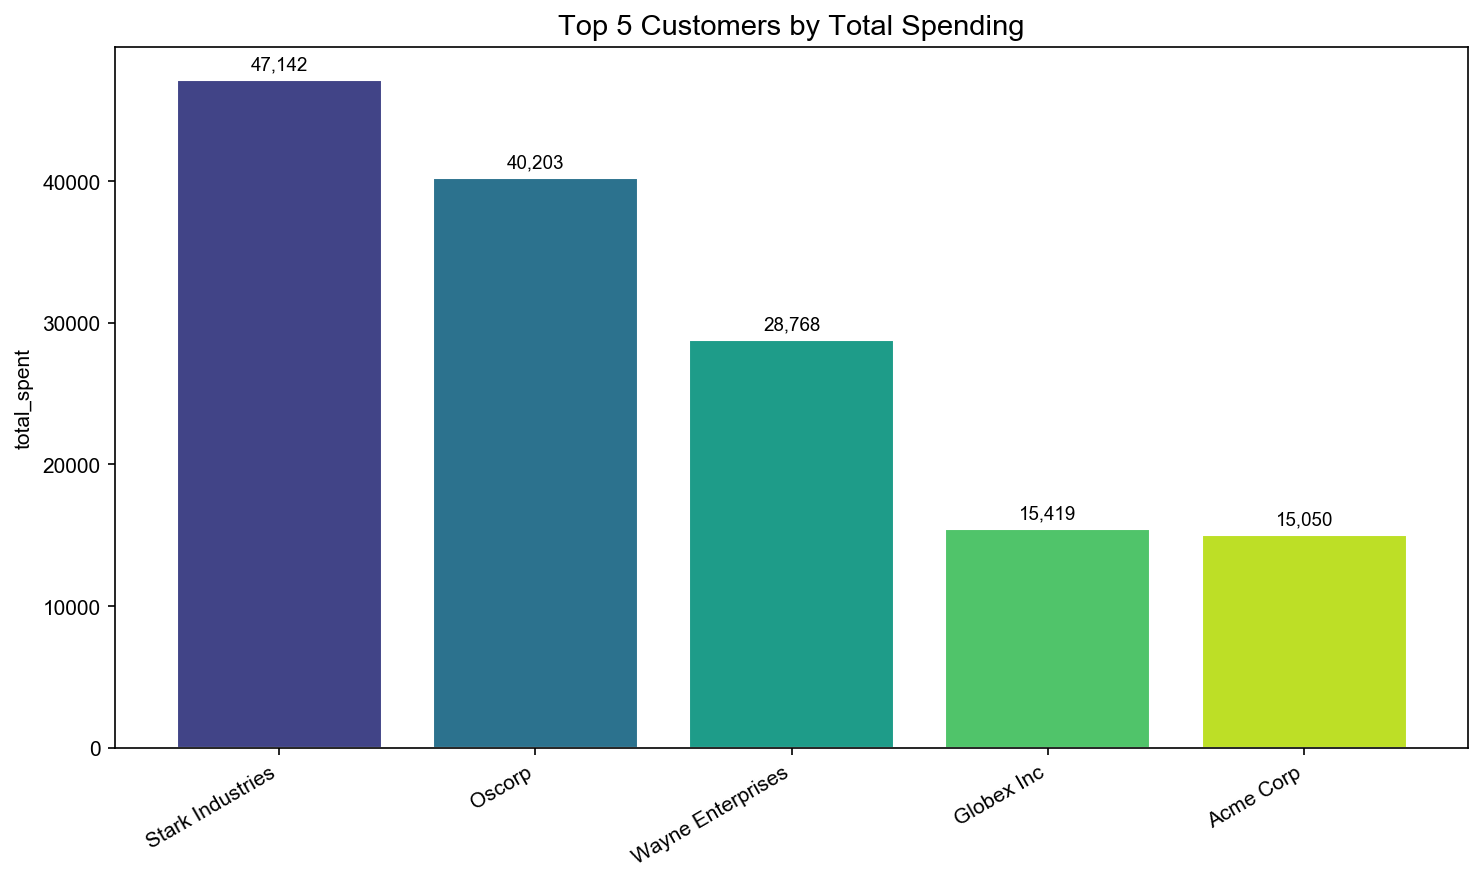

📊 chart_建议补货数量_横向柱状图_.png


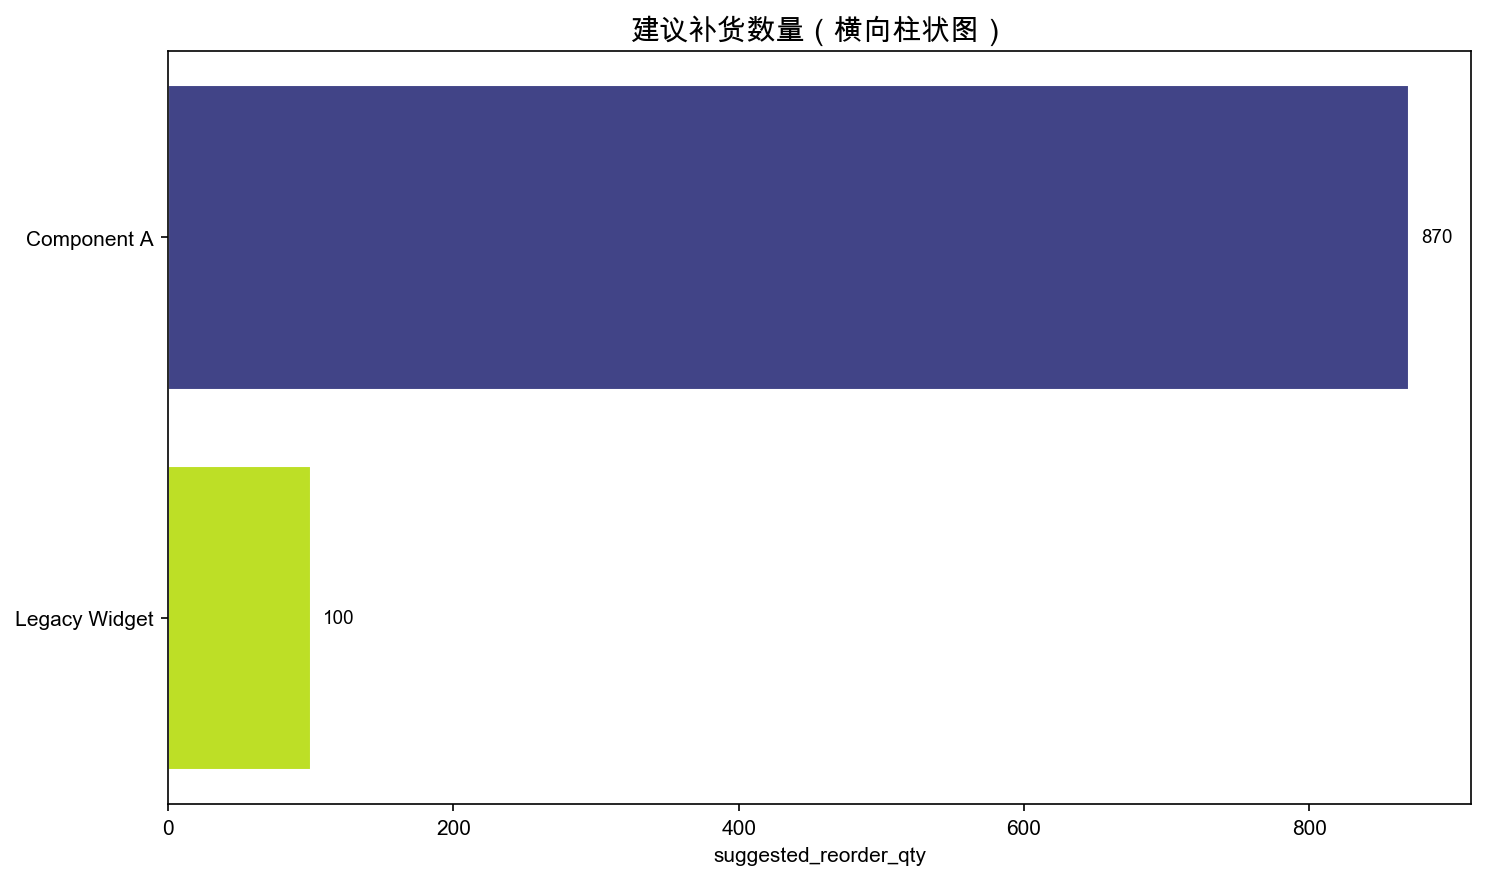

📊 chart_按产品类别统计销售占比.png


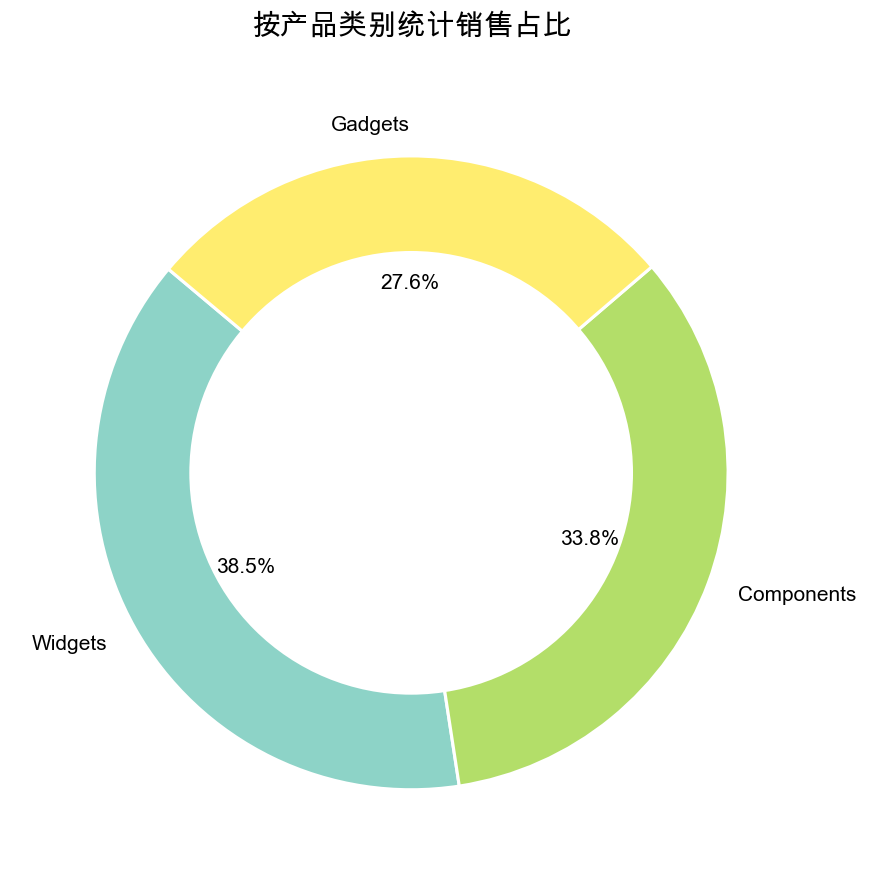

In [8]:
from IPython.display import Image, display
import glob

chart_dir = root_dir / "enterprise_data"
charts = sorted(chart_dir.glob("chart_*.png"))

if charts:
    print(f"Found {len(charts)} chart(s):\n")
    for chart in charts:
        print(f"📊 {chart.name}")
        display(Image(filename=str(chart)))
else:
    print("No charts found. Run the test queries first.")

## 6. 结论

通过这个 Notebook，我们验证了 **Progressive Disclosure** 在 SQL + 可视化场景下的效果：

1. **Token 效率**：Agent 启动时只加载了技能名称和描述，而非完整 Schema
2. **按需加载**：遇到销售问题时加载 `sales_analytics`，遇到库存问题时加载 `inventory_management`
3. **多工具协作**：Agent 组合使用 `read_skill` → `execute_sql` → `generate_chart` 完成端到端任务
4. **业务专家自治**：不同的业务团队可以独立维护各自的 `SKILL.md`，互不干扰